<a href="https://colab.research.google.com/github/murtaza-aiml/python_ai_ml/blob/main/Decision_Tree_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Decision Tree Evaluation ===
Test Set Accuracy: 66.7%

=== Feature Importance (Which columns mattered most?) ===
fLength   : 0.0%
fWidth    : 0.0%
fSize     : 0.0%
fAlpha    : 100.0%
fDist     : 0.0%

New Telescope Signal Prediction: Gamma-Ray Signal (1)


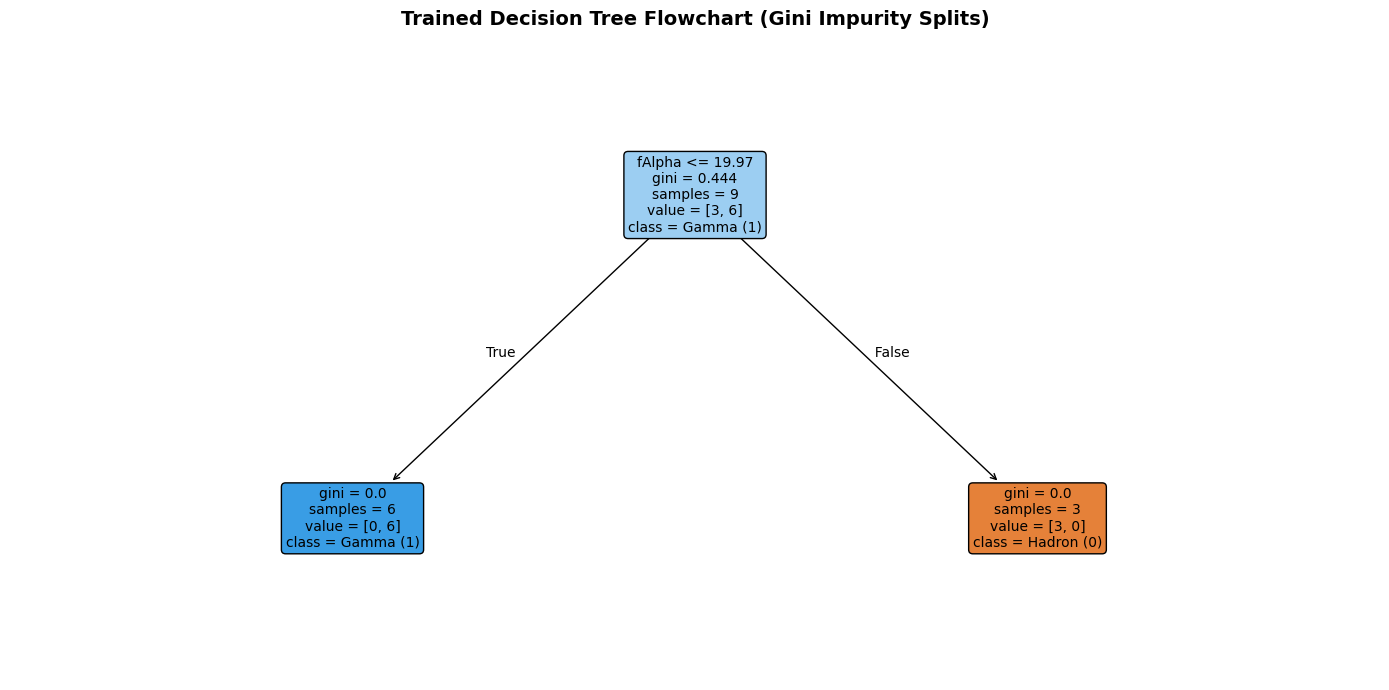

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

# ==========================================
# === 1. SETUP TELESCOPE SAMPLE DATASET  ===
# ==========================================
# Features from the MAGIC Gamma Telescope dataset
data = {
    'fLength': [28.79, 31.60, 162.05, 23.81, 75.13, 51.62, 48.24, 26.78, 96.23, 46.76, 62.77, 18.85],
    'fWidth':  [16.00, 11.72, 136.03, 9.57,  30.92, 21.15, 17.35, 13.84, 46.51, 15.19, 29.91, 9.58],
    'fSize':   [2.64,  2.51,  4.06,   2.33,  3.16,  2.90,  3.03,  2.46,  3.26,  2.57,  3.33,  2.31],
    'fAlpha':  [40.09, 6.39,  76.96,  10.44, 4.64,  3.61,  8.53,  22.96, 43.14, 1.29,  33.76, 16.98],
    'fDist':   [81.88, 205.26,256.78, 116.73,356.46,238.09,180.93,145.53,248.29,102.28,302.78,114.64],
    'class':   ['g',   'g',   'h',    'g',   'g',   'g',   'g',   'h',   'h',   'g',   'h',   'g']
}

df = pd.DataFrame(data)

# Convert text labels ('g' = Gamma-ray, 'h' = Hadron noise) into binary numbers (1 and 0)
df['class'] = df['class'].map({'g': 1, 'h': 0})

# Separate Features (X) and Target (y)
X = df.drop(columns=['class'])
y = df['class']


# ==========================================
# === 2. TRAIN / TEST SPLIT              ===
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


# ==========================================
# === 3. TRAIN DECISION TREE MODEL       ===
# ==========================================
# Note: No StandardScaler needed for Tree models!
# max_depth=3 prevents the tree from growing too deep and memorizing noise
tree_model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)


# ==========================================
# === 4. EVALUATE & INSPECT RULES        ===
# ==========================================
y_pred = tree_model.predict(X_test)
accuracy = tree_model.score(X_test, y_test)

print("=== Decision Tree Evaluation ===")
print(f"Test Set Accuracy: {accuracy * 100:.1f}%\n")

print("=== Feature Importance (Which columns mattered most?) ===")
for col, importance in zip(X.columns, tree_model.feature_importances_):
    print(f"{col:10}: {importance * 100:.1f}%")

# Predict on a new telescope flash: [fLength=30.0, fWidth=12.0, fSize=2.5, fAlpha=5.0, fDist=150.0]
new_flash = pd.DataFrame([[30.0, 12.0, 2.5, 5.0, 150.0]], columns=X.columns)
prediction = tree_model.predict(new_flash)[0]
label = "Gamma-Ray Signal (1)" if prediction == 1 else "Hadron Noise (0)"
print(f"\nNew Telescope Signal Prediction: {label}")


# ==========================================
# === 5. PLOT THE DECISION TREE FLOWCHART ===
# ==========================================
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=['Hadron (0)', 'Gamma (1)'],
    filled=True,      # Colors boxes: Orange = Hadron (0), Blue = Gamma (1)
    rounded=True,
    fontsize=10
)
plt.title("Trained Decision Tree Flowchart (Gini Impurity Splits)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
